
# Capítulo 7 — PINN para la ecuación de Van der Pol

Esta versión mantiene **la formulación teórica de PINN desarrollada en el trabajo** y no utiliza RNN ni la transformación de Liénard.

Se resuelve \[\dot x_1=x_2,\qquad\dot x_2=\mu(1-x_1^2)x_2-x_1,\] con \[x_1(0)=2,\qquad x_2(0)=0.\]

La red aproxima \[\mathcal N_\theta(t)=(\hat x_1(t),\hat x_2(t))\] y los residuos son exactamente \[\mathcal R_1=\dot{\hat x}_1-\hat x_2,\]

\[
\mathcal R_2=
\dot{\hat x}_2-\mu(1-\hat x_1^2)\hat x_2+\hat x_1.
\]

### Mejoras numéricas de entrenamiento

La física y los residuos no se cambian. Se mejora el entrenamiento mediante:

- Condición inicial impuesta exactamente (*hard constraint*);
- Normalización temporal local;
- *Time-marching* causal por ventanas;
- Tamaño de ventana adaptativo;
- Adam + L-BFGS;
- `float64`;
- Referencia RK45 para la evaluación.

La idea es solucionar las dificultades de las PINN estándar en el régimen rígido sin cambiar el modelo matemático del trabajo.


In [ ]:

import os, math, time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.integrate import solve_ivp
from IPython.display import display

torch.set_default_dtype(torch.float64)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

MU_VALUES = [0.1, 1.0, 5.0, 15.0]
X0, Y0 = 2.0, 0.0
T_FINAL = 40.0
N_REF = 4001

WIDTH = 64
DEPTH = 4
N_COLLOC = 128

ADAM_ITERS = 600
ADAM_LR = 2e-3
LBFGS_ITERS = 100
LBFGS_HISTORY = 50

DX_CAP = 2.0
N_WINDOW_EVAL = 40

OUTPUT_DIR = "resultados_PINN_Van_der_Pol_FINAL"
FIG_DIR = os.path.join(OUTPUT_DIR, "figuras")
os.makedirs(FIG_DIR, exist_ok=True)

# Cambiar a False para una prueba rápida antes de ejecutar todo.
RUN_FULL = True
if not RUN_FULL:
    ADAM_ITERS = 20
    LBFGS_ITERS = 5
    N_COLLOC = 80
    N_REF = 501

print("Dispositivo:", DEVICE)
print("dtype:", torch.get_default_dtype())
print("mu:", MU_VALUES)
print("T_FINAL:", T_FINAL)


Dispositivo: cpu
dtype: torch.float64
mu: [0.1, 1.0, 5.0, 15.0]
T_FINAL: 40.0



## 1. Referencia numérica

La solución de referencia se calcula con RK45. No participa en el entrenamiento de la PINN; solamente se utiliza posteriormente para medir el error.

Esto es especialmente apropiado para los valores altos de \(\mu\), donde Van der Pol presenta un comportamiento rígido.


In [ ]:

def vdp_rhs(t, z, mu):
    x, y = z
    return [y, mu*(1.0-x*x)*y-x]

def vdp_jac(t, z, mu):
    x, y = z
    return [
        [0.0, 1.0],
        [-2.0*mu*x*y-1.0, mu*(1.0-x*x)]
    ]

def reference_solution(mu):
    t_eval = np.linspace(0.0, T_FINAL, N_REF)
    sol = solve_ivp(
        lambda t,z: vdp_rhs(t,z,mu),
        (0.0,T_FINAL),
        [X0,Y0],
        method="RK45",
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-11,
        dense_output=True
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

references = {}
for mu in MU_VALUES:
    sol = reference_solution(mu)
    references[mu] = sol
    print(f"mu={mu}: nfev={sol.nfev}, njev={sol.njev}, nlu={sol.nlu}")


mu=0.1: nfev=5066, njev=0, nlu=0
mu=1.0: nfev=8594, njev=0, nlu=0
mu=5.0: nfev=13922, njev=0, nlu=0
mu=15.0: nfev=15218, njev=0, nlu=0



## 2. Arquitectura PINN

Se utiliza una MLP con `tanh`, Xavier/Glorot y dos salidas. La red recibe tiempo y devuelve \(x_1,x_2\).


In [ ]:

class PINN(nn.Module):
    def __init__(self, width=WIDTH, depth=DEPTH):
        super().__init__()
        layers = [nn.Linear(1,width), nn.Tanh()]
        for _ in range(depth-1):
            layers += [nn.Linear(width,width), nn.Tanh()]
        layers += [nn.Linear(width,2)]
        self.net = nn.Sequential(*layers)

        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, s):
        return self.net(s)

def window_input(t, t_a, t_b):
    return 2.0*(t-t_a)/(t_b-t_a)-1.0

def hard_ic_solution(model, t, t_a, t_b, state_a):
    s = window_input(t,t_a,t_b)
    raw = model(s)
    state = torch.as_tensor(state_a,dtype=t.dtype,device=t.device).reshape(1,2)
    u = state + (t-t_a)*raw
    return u[:,0:1], u[:,1:2]



## 3. Residuos físicos

Se conservan exactamente los residuos de la formulación teórica:

\[
R_1=\dot x_1-x_2,
\qquad
R_2=\dot x_2-\mu(1-x_1^2)x_2+x_1.
\]

El escalamiento opcional del segundo residuo se usa únicamente como **preacondicionamiento numérico del optimizador**. La ecuación física y el residuo físico que se reportan al final permanecen sin escalar.


In [ ]:

def grad(output,input_tensor):
    return torch.autograd.grad(
        output,input_tensor,
        grad_outputs=torch.ones_like(output),
        create_graph=True,retain_graph=True
    )[0]

def residuals(model,t,mu,t_a,t_b,state_a):
    t = t.clone().detach().requires_grad_(True)
    x,y = hard_ic_solution(model,t,t_a,t_b,state_a)
    x_t = grad(x,t)
    y_t = grad(y,t)
    R1 = x_t-y
    R2 = y_t-mu*(1.0-x*x)*y+x
    return R1,R2,x,y

def loss_fn(model,t,mu,t_a,t_b,state_a):
    R1,R2,_,_ = residuals(model,t,mu,t_a,t_b,state_a)
    R2opt = R2/max(1.0,float(mu))
    L1 = torch.mean(R1**2)
    L2 = torch.mean(R2opt**2)
    return L1+L2,L1,L2



## 4. Entrenamiento causal por ventanas

En lugar de entrenar una sola PINN sobre todo \([0,40]\), se resuelve secuencialmente:

\[
[t_0,t_1], [t_1,t_2],\ldots
\]

El estado final de una ventana se convierte en la condición inicial de la siguiente. Esto reduce la acumulación de error de fase.

El tamaño \(h\) se adapta usando \[
\max |x_2|\,h,\] de manera que las transiciones rápidas reciben ventanas menores.


In [ ]:

def collocation(t_a,t_b,n=N_COLLOC):
    return torch.linspace(t_a,t_b,n,device=DEVICE).reshape(-1,1)

def train_window(model,t_a,t_b,state_a,mu,verbose=False):
    t_col = collocation(t_a,t_b)
    history=[]

    opt = torch.optim.Adam(model.parameters(),lr=ADAM_LR)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt,max(1,ADAM_ITERS))

    for it in range(ADAM_ITERS):
        opt.zero_grad(set_to_none=True)
        loss,L1,L2 = loss_fn(model,t_col,mu,t_a,t_b,state_a)
        loss.backward()
        opt.step()
        sched.step()

        history.append({
            "optimizer":"Adam","iteration":it+1,
            "loss":float(loss.detach().cpu()),
            "loss_R1":float(L1.detach().cpu()),
            "loss_R2":float(L2.detach().cpu())
        })

        if verbose and ((it+1)%max(1,ADAM_ITERS//5)==0):
            print(f"    Adam {it+1}/{ADAM_ITERS}: {loss.item():.3e}")

    if LBFGS_ITERS>0:
        lbfgs = torch.optim.LBFGS(
            model.parameters(),
            max_iter=LBFGS_ITERS,
            history_size=LBFGS_HISTORY,
            tolerance_grad=1e-12,
            tolerance_change=1e-14,
            line_search_fn="strong_wolfe"
        )
        count=[0]
        def closure():
            lbfgs.zero_grad()
            loss,L1,L2 = loss_fn(model,t_col,mu,t_a,t_b,state_a)
            loss.backward()
            count[0]+=1
            history.append({
                "optimizer":"L-BFGS","iteration":count[0],
                "loss":float(loss.detach().cpu()),
                "loss_R1":float(L1.detach().cpu()),
                "loss_R2":float(L2.detach().cpu())
            })
            return loss
        lbfgs.step(closure)

    with torch.no_grad():
        te=torch.tensor([[t_b]],device=DEVICE)
        xe,ye=hard_ic_solution(model,te,t_a,t_b,state_a)
        state_b=(float(xe.item()),float(ye.item()))

    return state_b,history

def predict_window(model,t_a,t_b,state_a,n=N_WINDOW_EVAL):
    ts=torch.linspace(t_a,t_b,n,device=DEVICE).reshape(-1,1)
    with torch.no_grad():
        x,y=hard_ic_solution(model,ts,t_a,t_b,state_a)
    return ts.cpu().numpy().ravel(),x.cpu().numpy().ravel(),y.cpu().numpy().ravel()

def approx_period(mu):
    return max(2*np.pi,(3-2*np.log(2))*mu)

def solve_pinn(mu,verbose=True):
    model=PINN().to(DEVICE)

    # Ventanas iniciales según el régimen; la política anterior era demasiado restrictiva.
    if mu <= 0.1:
        h_max = 4.0
    elif mu <= 1.0:
        h_max = 3.0
    elif mu <= 5.0:
        h_max = 1.5
    else:
        h_max = 0.75

    h_min = max(1e-3, h_max/8)
    t_a=0.0
    h=h_max
    state_a=(X0,Y0)
    Tlist=[]; Xlist=[]; Ylist=[]
    windows=[]; histories=[]
    nwin=0; retry=0
    start=time.time()

    while t_a<T_FINAL-1e-12:
        h=min(h,T_FINAL-t_a)
        snapshot=copy.deepcopy(model.state_dict())
        state_b,hist=train_window(model,t_a,t_a+h,state_a,mu,verbose=False)
        tw,xw,yw=predict_window(model,t_a,t_a+h,state_a)

        max_y=float(np.max(np.abs(yw)))
        estimated_dx=max_y*h

        # Solo divide una ventana si el desplazamiento estimado es excesivo.
        if estimated_dx>DX_CAP and h>1.5*h_min:
            model.load_state_dict(snapshot)
            h=max(h/2,h_min)
            retry+=1
            if verbose:
                print(f"  ventana dividida: t={t_a:.3f}, nuevo h={h:.5f}, max|x2|={max_y:.3f}")
            continue

        nwin+=1
        if Tlist:
            tw,xw,yw=tw[1:],xw[1:],yw[1:]
        Tlist.append(tw); Xlist.append(xw); Ylist.append(yw)

        for r in hist:
            r.update({"mu":mu,"t_a":t_a,"t_b":t_a+h})
        histories.extend(hist)
        windows.append({
            "mu":mu,"window":nwin,"t_a":t_a,"t_b":t_a+h,
            "h":h,"max_abs_x2":max_y,
            "estimated_dx":estimated_dx,"retry_total":retry
        })

        if verbose:
            print(f"  ventana {nwin:3d}: [{t_a:.4f},{t_a+h:.4f}] h={h:.5f} max|x2|={max_y:.4f}")

        state_a=state_b
        t_a+=h
        # Aumenta de nuevo la ventana después de tramos difíciles.
        h=min(h_max,h*1.5)


    elapsed=time.time()-start

    t=np.concatenate(Tlist); x=np.concatenate(Xlist); y=np.concatenate(Ylist)
    order=np.argsort(t)

    return {
        "model":model,
        "t":t[order],"x":x[order],"y":y[order],
        "windows":pd.DataFrame(windows),
        "history":pd.DataFrame(histories),
        "n_windows":nwin,"n_retry":retry,
        "training_time_s":elapsed
    }



## 5. Métricas y ejecución

Se calculan MSE, MAE, RMSE, error relativo \(L^2\), \(L^\infty\) y \(R^2\), además del residuo físico global.

La referencia se usa solamente aquí, después de completar el entrenamiento.


In [ ]:

def metrics(pred,ref):
    e=pred-ref
    mse=np.mean(e**2)
    mae=np.mean(np.abs(e))
    rmse=np.sqrt(mse)
    rel=np.linalg.norm(e)/(np.linalg.norm(ref)+1e-15)
    linf=np.max(np.abs(e))
    r2=1-np.sum(e**2)/(np.sum((ref-ref.mean())**2)+1e-15)
    return {"MSE":mse,"MAE":mae,"RMSE":rmse,
            "Relative_L2":rel,"Linf":linf,"R2":r2}

PINN_RESULTS={}
rows=[]

total_start=time.time()

for mu in MU_VALUES:
    print("\n"+"="*80)
    print(f"PINN — mu={mu}")
    print("="*80)

    result=solve_pinn(mu,verbose=True)
    PINN_RESULTS[mu]=result

    ref=references[mu]
    xpred=np.interp(ref.t,result["t"],result["x"])
    ypred=np.interp(ref.t,result["t"],result["y"])

    mx=metrics(xpred,ref.y[0])
    my=metrics(ypred,ref.y[1])

    # Residuo físico mediante diferencias sobre la malla independiente.
    dxdt=np.gradient(xpred,ref.t)
    dydt=np.gradient(ypred,ref.t)
    R1=dxdt-ypred
    R2=dydt-mu*(1-xpred**2)*ypred+xpred

    rows.append({
        "mu":mu,
        "x_MSE":mx["MSE"],"x_MAE":mx["MAE"],"x_RMSE":mx["RMSE"],
        "x_Relative_L2":mx["Relative_L2"],"x_Linf":mx["Linf"],"x_R2":mx["R2"],
        "x2_MSE":my["MSE"],"x2_MAE":my["MAE"],"x2_RMSE":my["RMSE"],
        "x2_Relative_L2":my["Relative_L2"],"x2_Linf":my["Linf"],"x2_R2":my["R2"],
        "R1_RMS":np.sqrt(np.mean(R1**2)),
        "R2_RMS":np.sqrt(np.mean(R2**2)),
        "R1_max":np.max(np.abs(R1)),
        "R2_max":np.max(np.abs(R2)),
        "n_windows":result["n_windows"],
        "n_retry":result["n_retry"],
        "training_time_s":result["training_time_s"],
        "RK45_nfev":ref.nfev
    })

results_df=pd.DataFrame(rows)
display(results_df)
print(f"Tiempo total: {time.time()-total_start:.1f} s")



PINN — mu=0.1
  ventana dividida: t=0.000, nuevo h=2.00000, max|x2|=2.009
  ventana dividida: t=0.000, nuevo h=1.00000, max|x2|=2.011
  ventana   1: [0.0000,1.0000] h=1.00000 max|x2|=1.5690
  ventana dividida: t=1.000, nuevo h=0.75000, max|x2|=2.011
  ventana   2: [1.0000,1.7500] h=0.75000 max|x2|=2.0114
  ventana dividida: t=1.750, nuevo h=0.56250, max|x2|=2.010
  ventana   3: [1.7500,2.3125] h=0.56250 max|x2|=2.0104
  ventana   4: [2.3125,3.1562] h=0.84375 max|x2|=1.5905
  ventana dividida: t=3.156, nuevo h=0.63281, max|x2|=1.829
  ventana   5: [3.1562,3.7891] h=0.63281 max|x2|=1.1197
  ventana   6: [3.7891,4.7383] h=0.94922 max|x2|=1.9956
  ventana dividida: t=4.738, nuevo h=0.71191, max|x2|=2.011
  ventana   7: [4.7383,5.4502] h=0.71191 max|x2|=2.0115
  ventana   8: [5.4502,6.5181] h=1.06787 max|x2|=1.5988
  ventana dividida: t=6.518, nuevo h=0.80090, max|x2|=2.012
  ventana   9: [6.5181,7.3190] h=0.80090 max|x2|=1.6032
  ventana dividida: t=7.319, nuevo h=0.60068, max|x2|=2.011
 

,mu,x_MSE,x_MAE,x_RMSE,x_Relative_L2,x_Linf,x_R2,x2_MSE,x2_MAE,x2_RMSE,...,x2_Linf,x2_R2,R1_RMS,R2_RMS,R1_max,R2_max,n_windows,n_retry,training_time_s,RK45_nfev
0,0.1,9.021778e-09,0.000074,0.000095,0.000068,0.000391,1.000000,7.192921e-09,0.000067,0.000085,...,0.000328,1.000000,0.002413,0.001643,0.027588,0.012208,51,31,385.413756,5066
1,1.0,1.633322e-07,0.000326,0.000404,0.000282,0.001118,1.000000,4.026529e-07,0.000469,0.000635,...,0.003243,1.000000,0.002227,0.005453,0.041194,0.111316,60,36,438.597952,8594
2,5.0,1.811520e-05,0.001831,0.004256,0.002711,0.024270,0.999993,4.467805e-04,0.006930,0.021137,...,0.140112,0.999800,0.003558,0.032815,0.140278,0.545765,55,25,360.569756,13922
3,15.0,2.790137e+00,1.125573,1.670370,1.019191,4.888097,-0.151013,2.689103e+00,0.288925,1.639848,...,20.719530,0.003665,0.564766,4.581310,9.583392,65.628117,54,0,237.191577,15218


Tiempo total: 1422.1 s



# 6. Gráficas principales

Cada figura principal tiene cuatro paneles:

1. \(x(t)\): RK45 vs PINN;
2. \(x_2(t)\): RK45 vs PINN;
3. Retrato de fase;
4. Error absoluto en escala logarítmica.


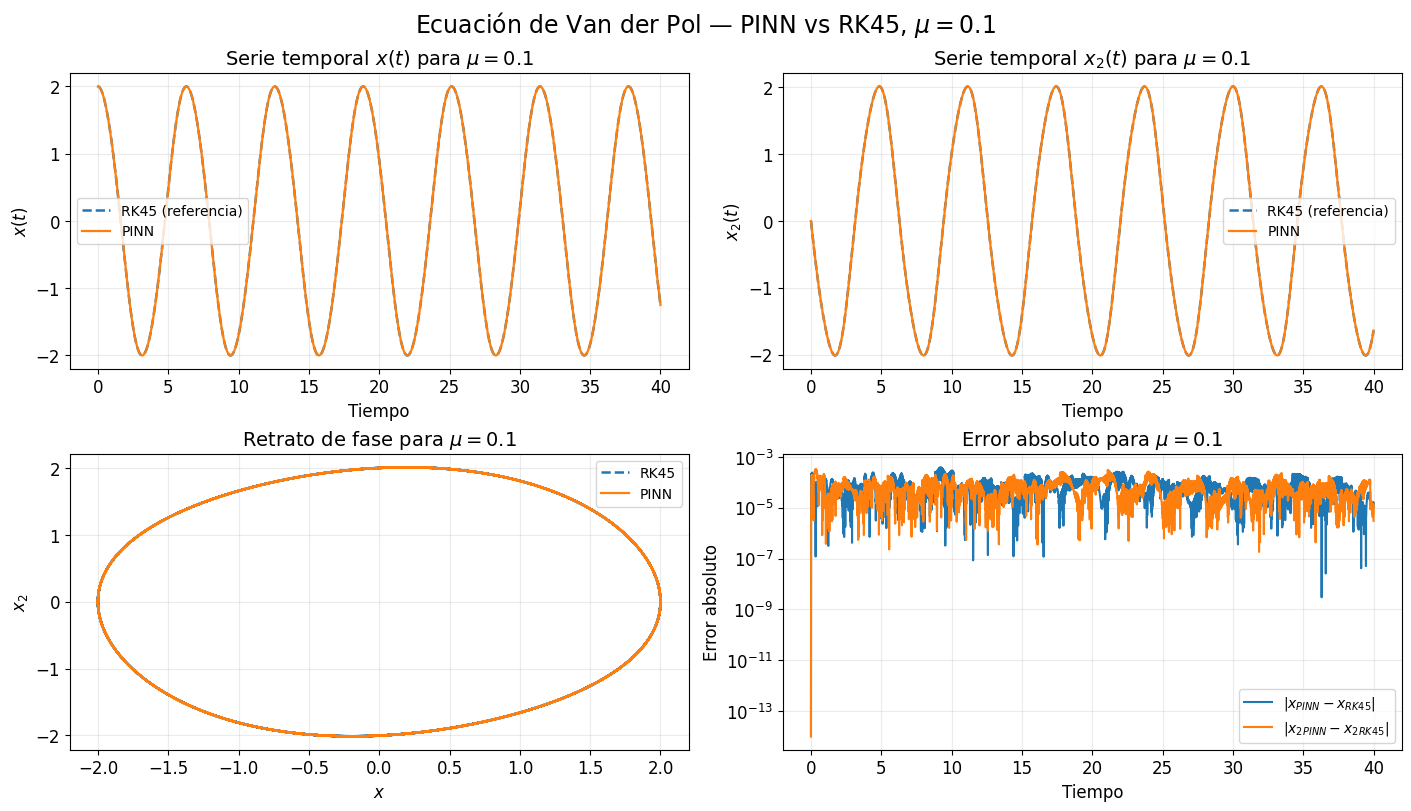

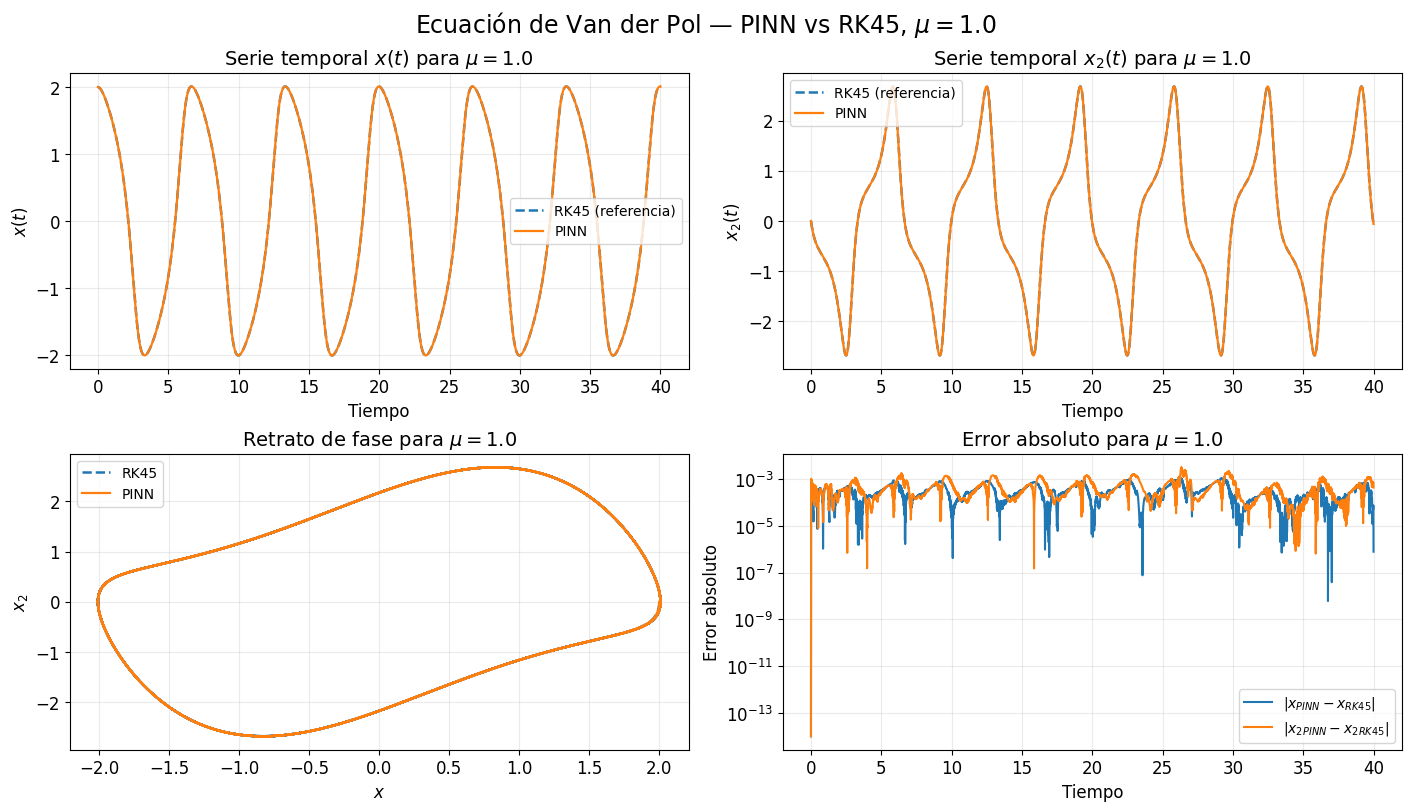

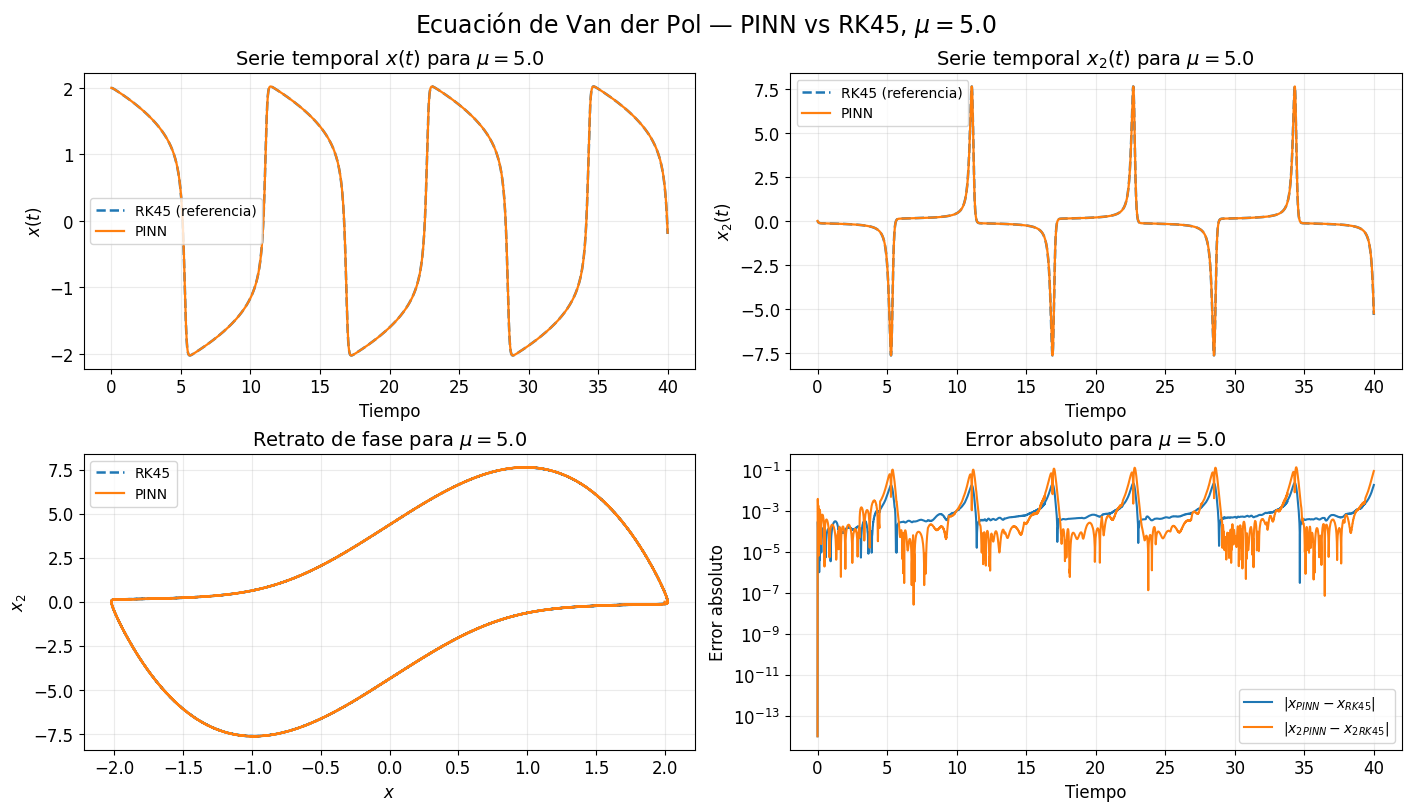

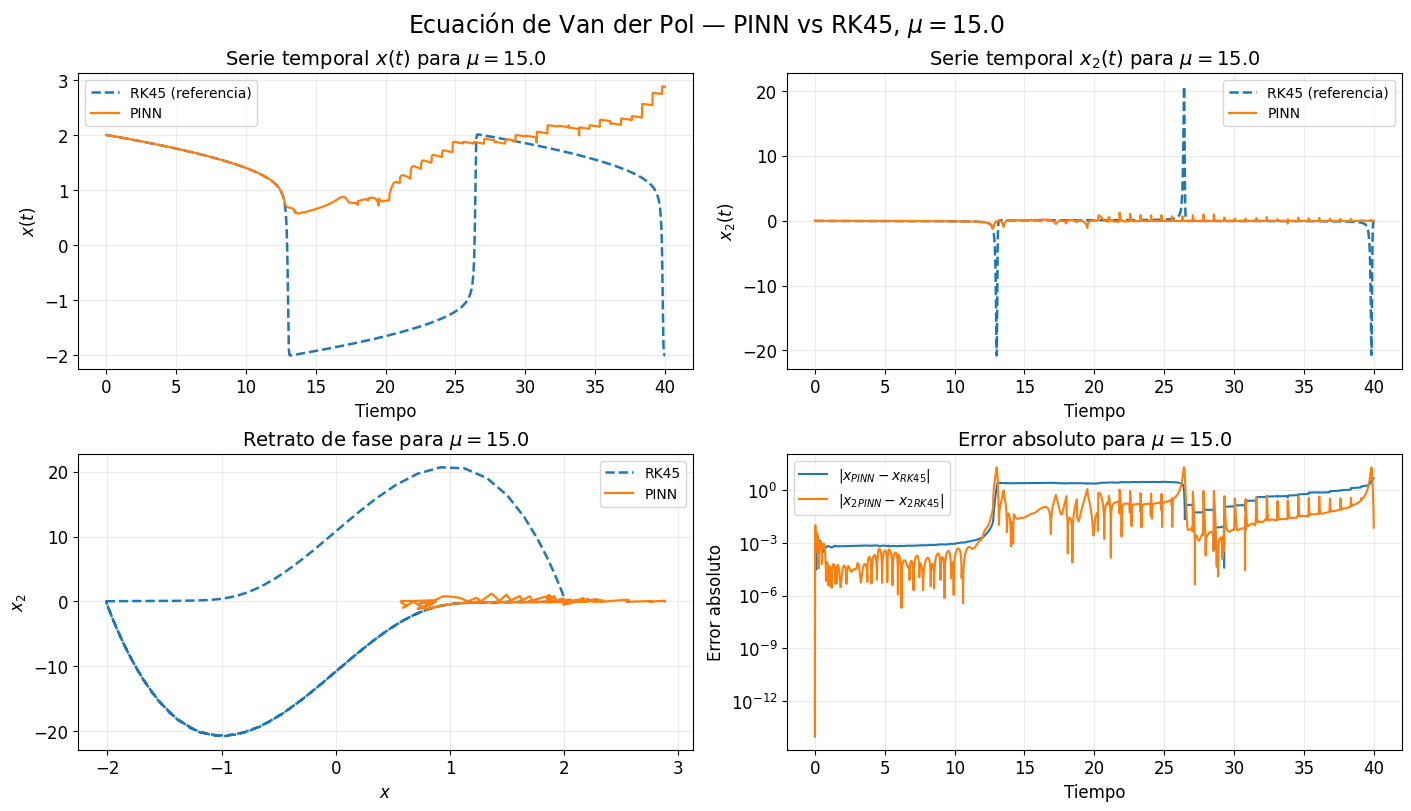

In [ ]:

plt.rcParams.update({
    "font.size":12,
    "axes.titlesize":14,
    "axes.labelsize":12,
    "legend.fontsize":10
})

def main_figure(mu):
    ref=references[mu]
    res=PINN_RESULTS[mu]

    tp=res["t"]; xp=res["x"]; yp=res["y"]
    x=np.interp(ref.t,tp,xp)
    y=np.interp(ref.t,tp,yp)

    ex=np.abs(x-ref.y[0])
    ey=np.abs(y-ref.y[1])

    fig,ax=plt.subplots(2,2,figsize=(14,8),constrained_layout=True)

    ax[0,0].plot(ref.t,ref.y[0],"--",lw=1.8,label="RK45 (referencia)")
    ax[0,0].plot(tp,xp,lw=1.6,label="PINN")
    ax[0,0].set_title(f"Serie temporal $x(t)$ para $\\mu={mu}$")
    ax[0,0].set_xlabel("Tiempo"); ax[0,0].set_ylabel("$x(t)$")
    ax[0,0].grid(True,alpha=.25); ax[0,0].legend()

    ax[0,1].plot(ref.t,ref.y[1],"--",lw=1.8,label="RK45 (referencia)")
    ax[0,1].plot(tp,yp,lw=1.6,label="PINN")
    ax[0,1].set_title(f"Serie temporal $x_2(t)$ para $\\mu={mu}$")
    ax[0,1].set_xlabel("Tiempo"); ax[0,1].set_ylabel("$x_2(t)$")
    ax[0,1].grid(True,alpha=.25); ax[0,1].legend()

    ax[1,0].plot(ref.y[0],ref.y[1],"--",lw=1.8,label="RK45")
    ax[1,0].plot(xp,yp,lw=1.6,label="PINN")
    ax[1,0].set_title(f"Retrato de fase para $\\mu={mu}$")
    ax[1,0].set_xlabel("$x$"); ax[1,0].set_ylabel("$x_2$")
    ax[1,0].grid(True,alpha=.25); ax[1,0].legend()

    ax[1,1].semilogy(ref.t,np.maximum(ex,1e-14),lw=1.5,label="$|x_{PINN}-x_{RK45}|$")
    ax[1,1].semilogy(ref.t,np.maximum(ey,1e-14),lw=1.5,label="$|x_2{}_{PINN}-x_2{}_{RK45}|$")
    ax[1,1].set_title(f"Error absoluto para $\\mu={mu}$")
    ax[1,1].set_xlabel("Tiempo"); ax[1,1].set_ylabel("Error absoluto")
    ax[1,1].grid(True,which="both",alpha=.25); ax[1,1].legend()

    fig.suptitle(f"Ecuación de Van der Pol — PINN vs RK45, $\\mu={mu}$",fontsize=17)

    path=os.path.join(FIG_DIR,f"PINN_mu_{str(mu).replace('.','_')}_principal.png")
    fig.savefig(path,dpi=300,bbox_inches="tight")
    plt.show()

for mu in MU_VALUES:
    main_figure(mu)


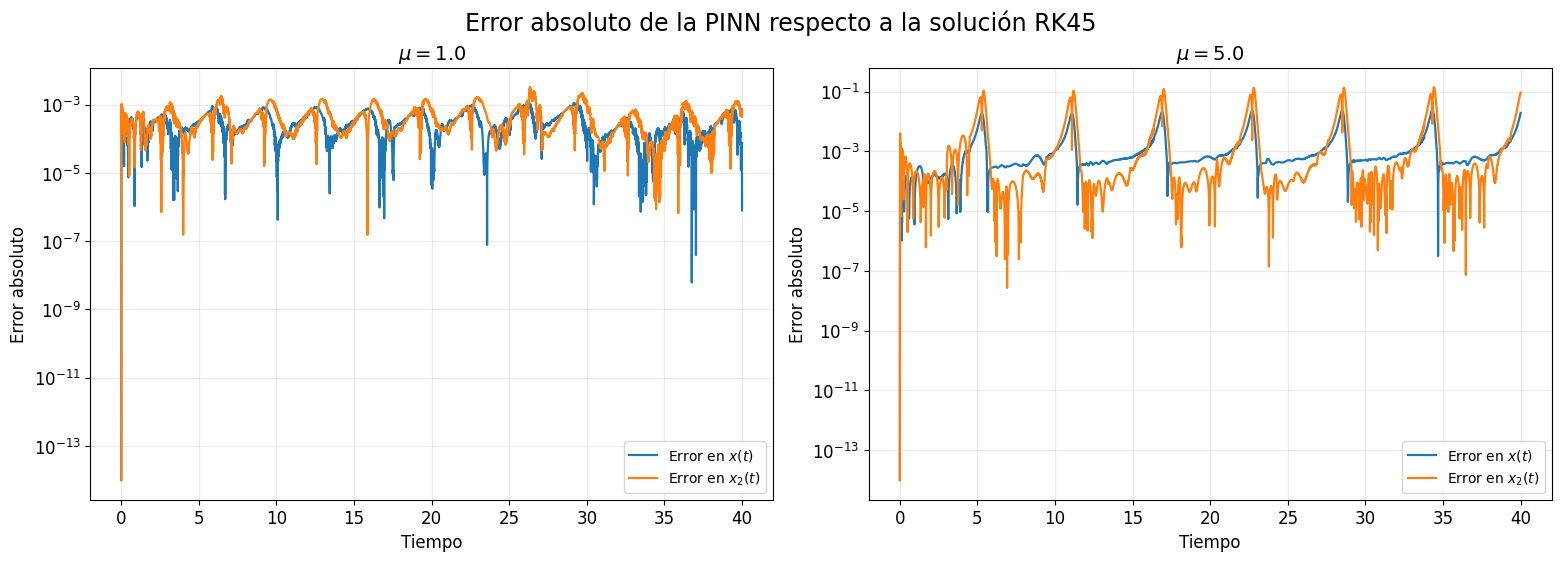

In [ ]:

# Figura de errores

selected=[m for m in [1.0,5.0] if m in MU_VALUES]
fig,axes=plt.subplots(1,2,figsize=(15.5,5.5),constrained_layout=True)

for ax,mu in zip(axes,selected):
    ref=references[mu]; res=PINN_RESULTS[mu]
    x=np.interp(ref.t,res["t"],res["x"])
    y=np.interp(ref.t,res["t"],res["y"])

    ax.semilogy(ref.t,np.maximum(np.abs(x-ref.y[0]),1e-14),
                lw=1.6,label="Error en $x(t)$")
    ax.semilogy(ref.t,np.maximum(np.abs(y-ref.y[1]),1e-14),
                lw=1.6,label="Error en $x_2(t)$")
    ax.set_title(f"$\\mu={mu}$")
    ax.set_xlabel("Tiempo"); ax.set_ylabel("Error absoluto")
    ax.grid(True,which="both",alpha=.25); ax.legend()

fig.suptitle("Error absoluto de la PINN respecto a la solución RK45",fontsize=17)
path=os.path.join(FIG_DIR,"PINN_error_absoluto_RK45_mu_1_mu_5.png")
fig.savefig(path,dpi=300,bbox_inches="tight")
plt.show()


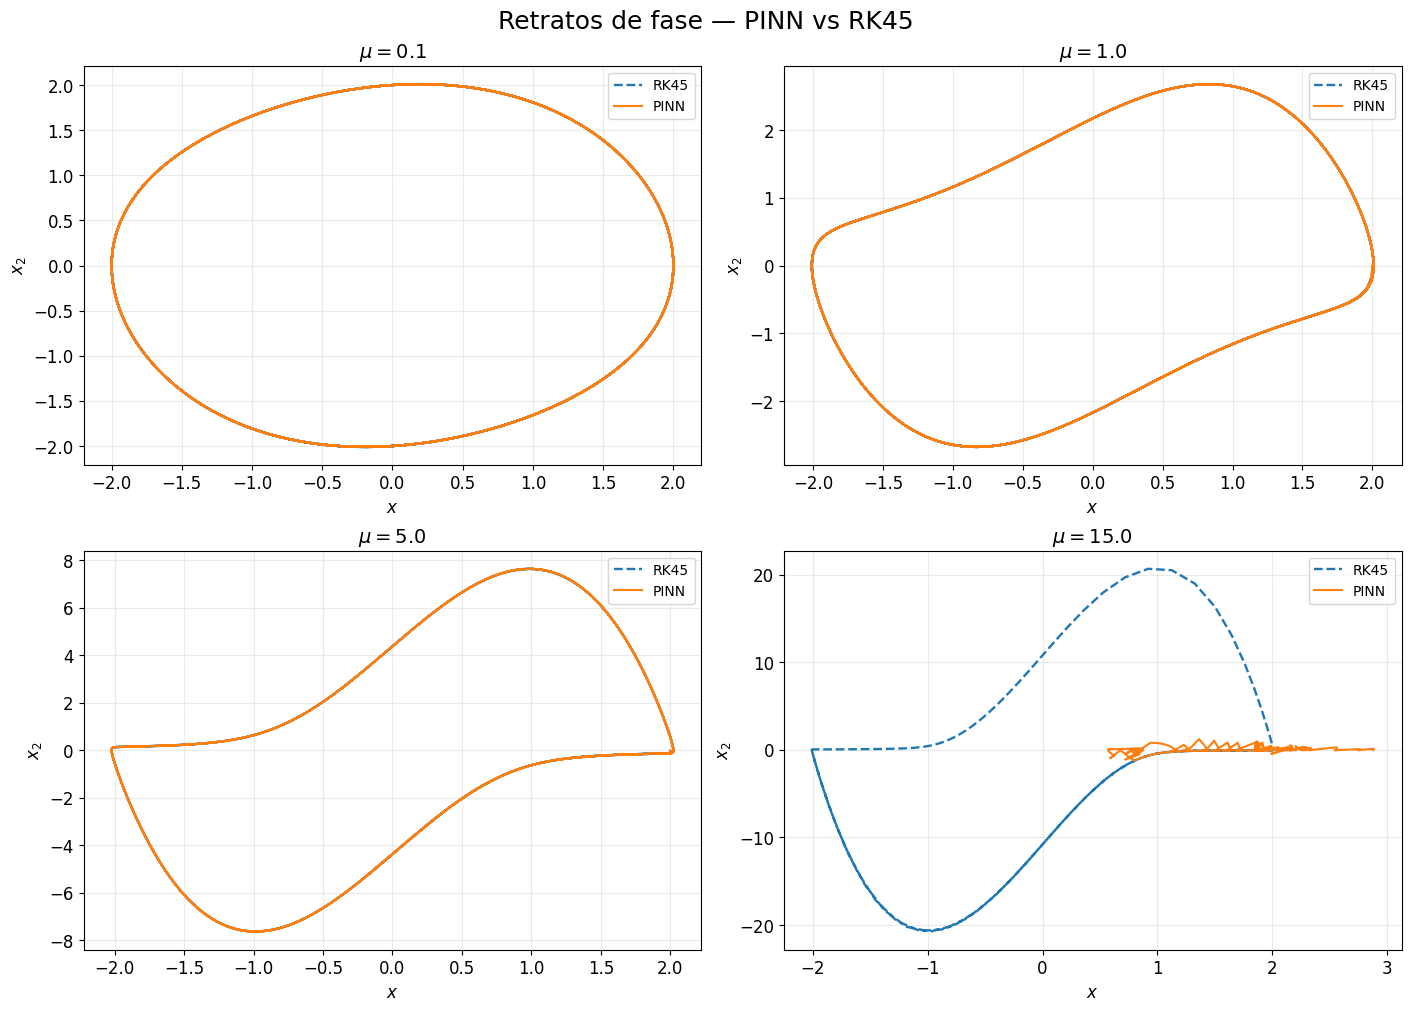

In [ ]:

# Retratos de fase comparativos 2x2

fig,axes=plt.subplots(2,2,figsize=(14,10),constrained_layout=True)

for ax,mu in zip(axes.flat,MU_VALUES):
    ref=references[mu]; res=PINN_RESULTS[mu]
    ax.plot(ref.y[0],ref.y[1],"--",lw=1.7,label="RK45")
    ax.plot(res["x"],res["y"],lw=1.5,label="PINN")
    ax.set_title(f"$\\mu={mu}$")
    ax.set_xlabel("$x$"); ax.set_ylabel("$x_2$")
    ax.grid(True,alpha=.25); ax.legend()

fig.suptitle("Retratos de fase — PINN vs RK45",fontsize=18)
path=os.path.join(FIG_DIR,"PINN_RK45_retratos_fase_2x2.png")
fig.savefig(path,dpi=300,bbox_inches="tight")
plt.show()


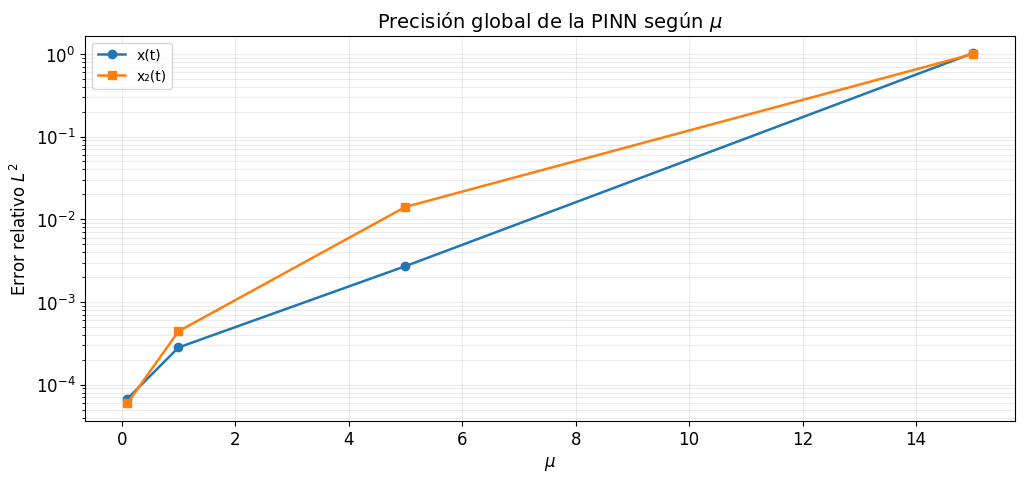

In [ ]:

# Error relativo L2 frente a mu

fig,ax=plt.subplots(figsize=(12,5))
ax.semilogy(results_df["mu"],results_df["x_Relative_L2"],
            marker="o",lw=1.8,label="x(t)")
ax.semilogy(results_df["mu"],results_df["x2_Relative_L2"],
            marker="s",lw=1.8,label="x₂(t)")
ax.set_xlabel("$\\mu$")
ax.set_ylabel("Error relativo $L^2$")
ax.set_title("Precisión global de la PINN según $\\mu$")
ax.grid(True,which="both",alpha=.25)
ax.legend()
path=os.path.join(FIG_DIR,"PINN_error_relativo_L2_vs_mu.png")
fig.savefig(path,dpi=300,bbox_inches="tight")
plt.show()


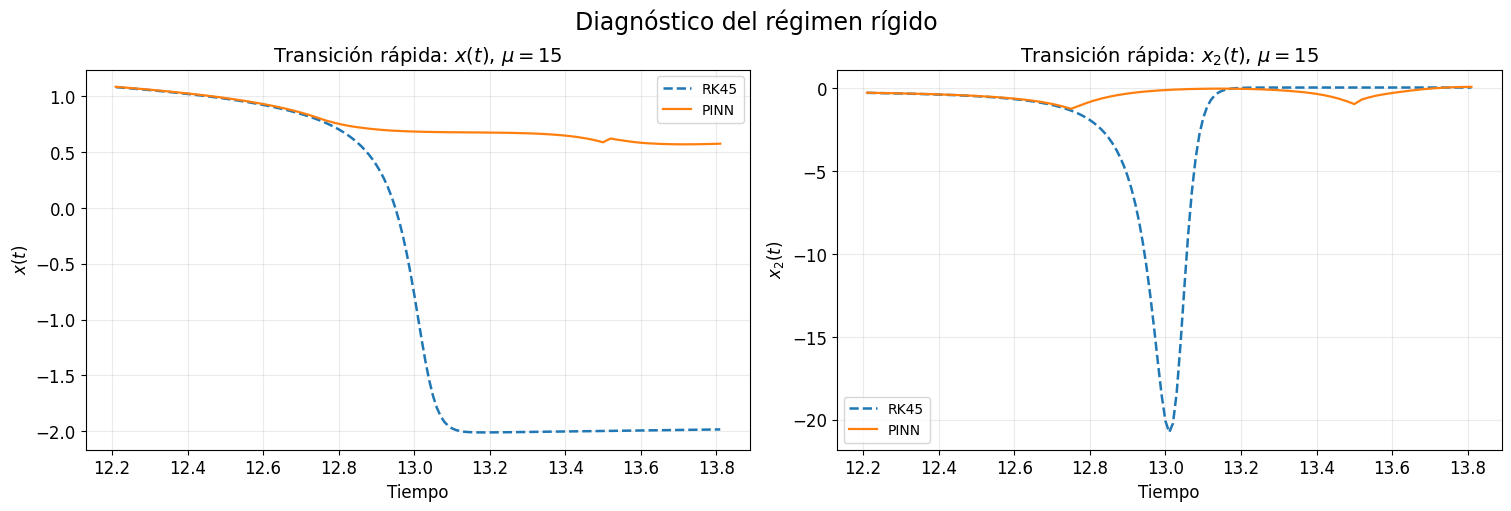

In [ ]:

# Transición rápida para mu=15

if 15.0 in MU_VALUES:
    mu=15.0
    ref=references[mu]; res=PINN_RESULTS[mu]
    idx=int(np.argmax(np.abs(ref.y[1])))
    tc=ref.t[idx]
    w=.8
    mask=(ref.t>=max(0,tc-w))&(ref.t<=min(T_FINAL,tc+w))
    tz=ref.t[mask]

    xz=np.interp(tz,res["t"],res["x"])
    yz=np.interp(tz,res["t"],res["y"])

    fig,axes=plt.subplots(1,2,figsize=(15,5),constrained_layout=True)

    axes[0].plot(tz,ref.y[0][mask],"--",lw=1.8,label="RK45")
    axes[0].plot(tz,xz,lw=1.6,label="PINN")
    axes[0].set_title("Transición rápida: $x(t)$, $\\mu=15$")
    axes[0].set_xlabel("Tiempo"); axes[0].set_ylabel("$x(t)$")
    axes[0].grid(True,alpha=.25); axes[0].legend()

    axes[1].plot(tz,ref.y[1][mask],"--",lw=1.8,label="RK45")
    axes[1].plot(tz,yz,lw=1.6,label="PINN")
    axes[1].set_title("Transición rápida: $x_2(t)$, $\\mu=15$")
    axes[1].set_xlabel("Tiempo"); axes[1].set_ylabel("$x_2(t)$")
    axes[1].grid(True,alpha=.25); axes[1].legend()

    fig.suptitle("Diagnóstico del régimen rígido",fontsize=17)
    path=os.path.join(FIG_DIR,"PINN_zoom_transicion_mu_15.png")
    fig.savefig(path,dpi=300,bbox_inches="tight")
    plt.show()


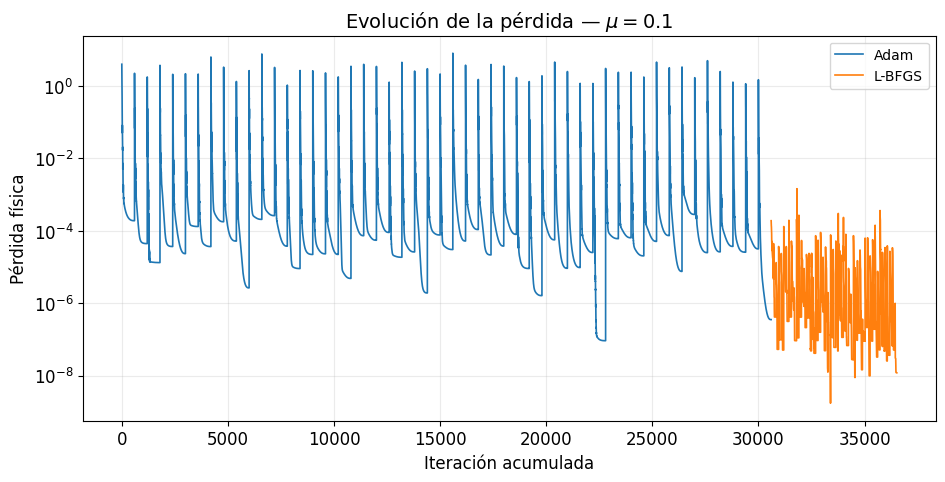

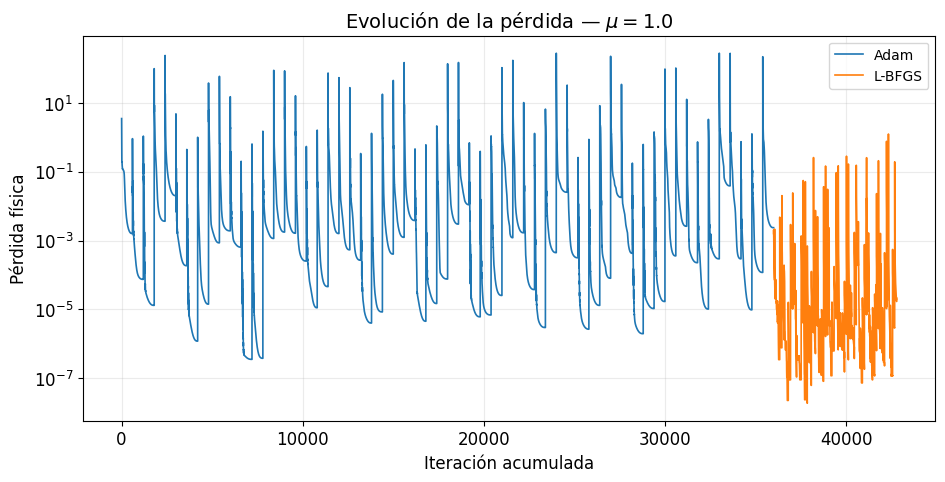

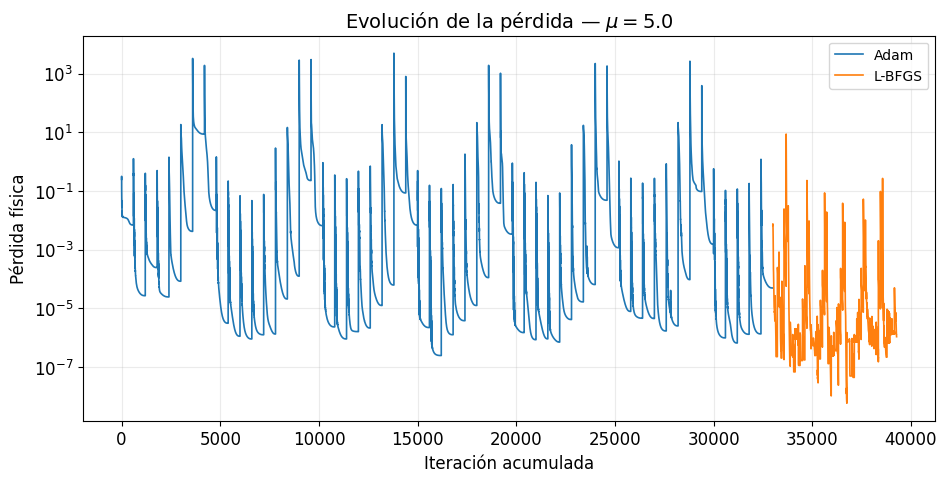

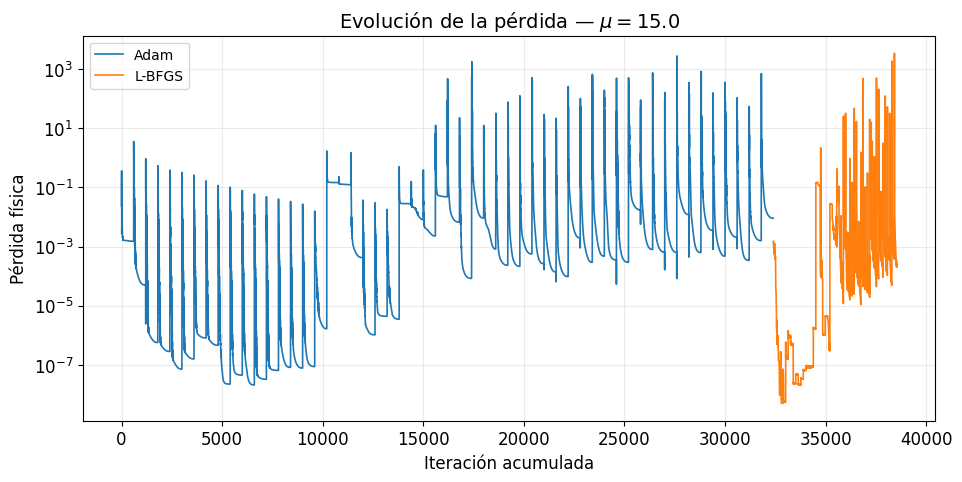

In [ ]:

# Evolución de la pérdida

for mu in MU_VALUES:
    hist=PINN_RESULTS[mu]["history"]
    if hist.empty:
        continue

    fig,ax=plt.subplots(figsize=(11,5))
    adam=hist[hist.optimizer=="Adam"]
    lbfgs=hist[hist.optimizer=="L-BFGS"]

    if len(adam):
        ax.semilogy(np.arange(len(adam)),np.maximum(adam.loss,1e-16),
                    lw=1.2,label="Adam")
    if len(lbfgs):
        start=len(adam)
        ax.semilogy(np.arange(start,start+len(lbfgs)),
                    np.maximum(lbfgs.loss,1e-16),
                    lw=1.2,label="L-BFGS")

    ax.set_title(f"Evolución de la pérdida — $\\mu={mu}$")
    ax.set_xlabel("Iteración acumulada")
    ax.set_ylabel("Pérdida física")
    ax.grid(True,which="both",alpha=.25)
    ax.legend()

    path=os.path.join(FIG_DIR,f"PINN_loss_mu_{str(mu).replace('.','_')}.png")
    fig.savefig(path,dpi=300,bbox_inches="tight")
    plt.show()


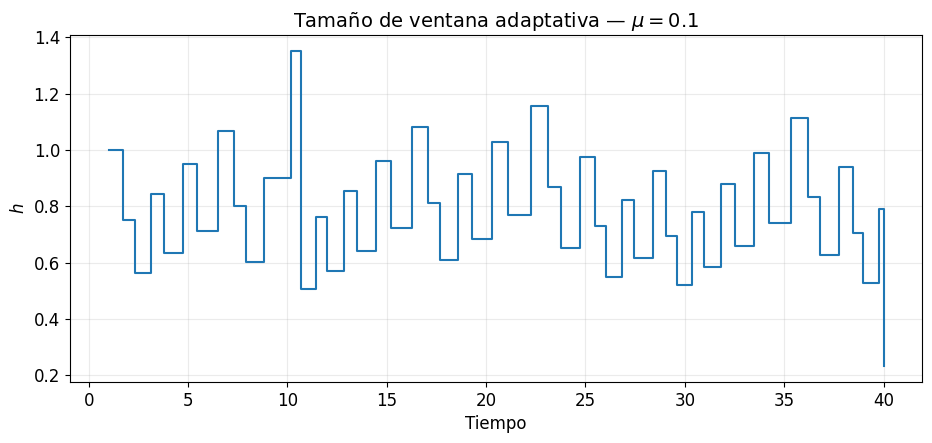

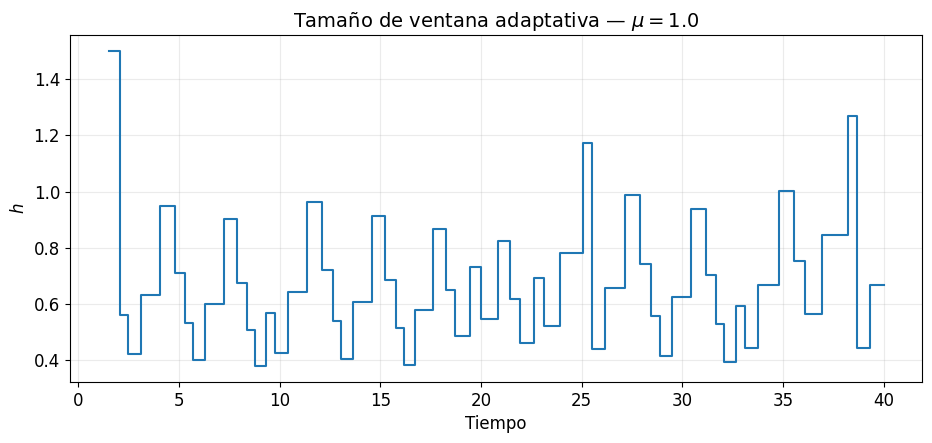

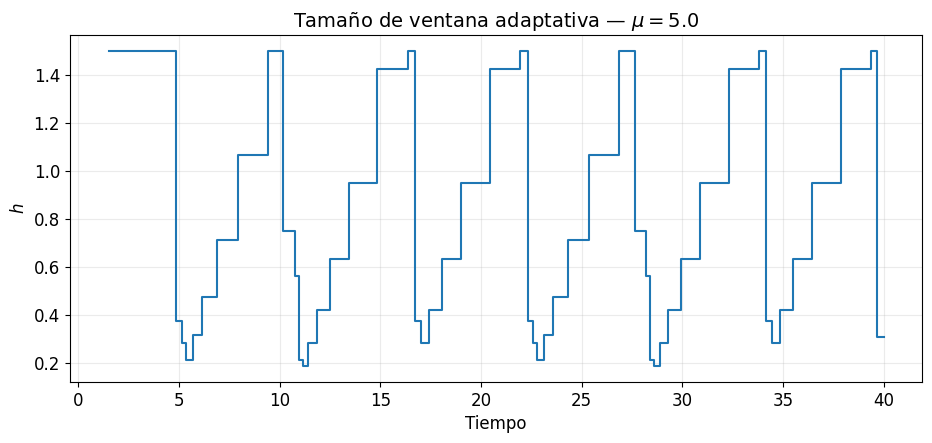

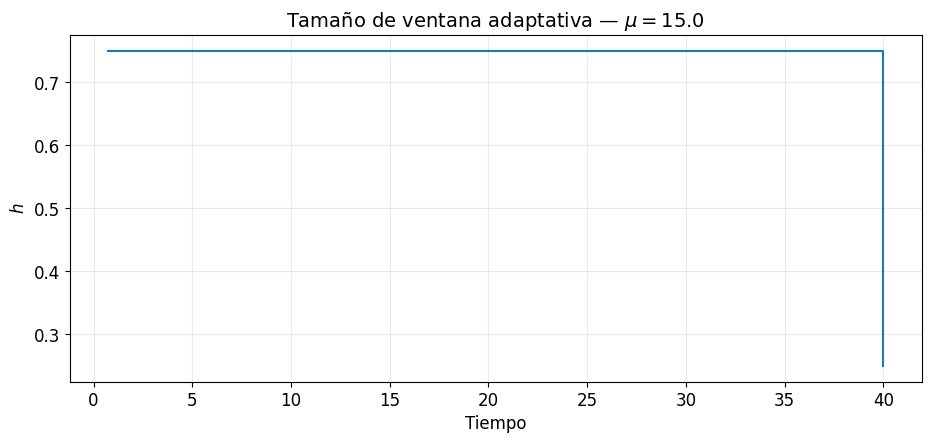

In [ ]:

# Tamaño de ventanas adaptativas

for mu in MU_VALUES:
    w=PINN_RESULTS[mu]["windows"]
    if w.empty:
        continue

    fig,ax=plt.subplots(figsize=(11,4.5))
    ax.step(w.t_b,w.h,where="post",lw=1.5)
    ax.set_title(f"Tamaño de ventana adaptativa — $\\mu={mu}$")
    ax.set_xlabel("Tiempo"); ax.set_ylabel("$h$")
    ax.grid(True,alpha=.25)

    path=os.path.join(FIG_DIR,f"PINN_ventanas_mu_{str(mu).replace('.','_')}.png")
    fig.savefig(path,dpi=300,bbox_inches="tight")
    plt.show()



## 7. Exportación y verificaciones

Se guardan las métricas, el historial de entrenamiento y las ventanas adaptativas. También se comprueba que las condiciones iniciales sean exactas.


In [ ]:

metrics_path=os.path.join(OUTPUT_DIR,"resultados_PINN_Van_der_Pol.csv")
results_df.to_csv(metrics_path,index=False)

histories=[]
windows=[]
for mu in MU_VALUES:
    h=PINN_RESULTS[mu]["history"].copy()
    w=PINN_RESULTS[mu]["windows"].copy()
    if not h.empty: histories.append(h)
    if not w.empty: windows.append(w)

history_df=pd.concat(histories,ignore_index=True) if histories else pd.DataFrame()
windows_df=pd.concat(windows,ignore_index=True) if windows else pd.DataFrame()

history_path=os.path.join(OUTPUT_DIR,"historial_entrenamiento_PINN.csv")
windows_path=os.path.join(OUTPUT_DIR,"historial_ventanas_PINN.csv")

history_df.to_csv(history_path,index=False)
windows_df.to_csv(windows_path,index=False)

checks=[]
for mu in MU_VALUES:
    r=PINN_RESULTS[mu]
    checks.append({
        "mu":mu,
        "finite":bool(np.all(np.isfinite(r["x"])) and np.all(np.isfinite(r["y"]))),
        "x(0)":r["x"][0],
        "x2(0)":r["y"][0],
        "error_IC_x":abs(r["x"][0]-X0),
        "error_IC_x2":abs(r["y"][0]-Y0),
        "t_final":r["t"][-1],
        "n_windows":r["n_windows"],
        "n_retry":r["n_retry"]
    })

checks_df=pd.DataFrame(checks)
display(checks_df)

assert checks_df["finite"].all()
assert checks_df["error_IC_x"].max()<1e-10
assert checks_df["error_IC_x2"].max()<1e-10

print("✓ Resultados guardados en:", OUTPUT_DIR)
print("✓ Figuras guardadas en:", FIG_DIR)
print("✓ Todas las verificaciones finalizaron correctamente.")


,mu,finite,x(0),x2(0),error_IC_x,error_IC_x2,t_final,n_windows,n_retry
0,0.1,True,2.0,0.0,0.0,0.0,40.0,51,31
1,1.0,True,2.0,0.0,0.0,0.0,40.0,60,36
2,5.0,True,2.0,0.0,0.0,0.0,40.0,55,25
3,15.0,True,2.0,0.0,0.0,0.0,40.0,54,0


✓ Resultados guardados en: resultados_PINN_Van_der_Pol_FINAL
✓ Figuras guardadas en: resultados_PINN_Van_der_Pol_FINAL/figuras
✓ Todas las verificaciones finalizaron correctamente.
